In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

torch.manual_seed(42)

In [2]:
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())

display(df.head())

Saving Lab_11_QnA_Dataset.csv to Lab_11_QnA_Dataset.csv
Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


In [3]:
df["question"] = df["question"].str.lower()

tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

X = pad_sequences(
    tokenizer.texts_to_sequences(df["question"]),
    padding="post"
)

y = df["answer_id"].values

X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

print("Preprocessing finished!")

Preprocessing finished!


In [9]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.emb = nn.Embedding(
            len(tokenizer.word_index) + 1, 16,
            padding_idx=0
        )

        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        mask = x != 0

        x, _ = self.rnn(self.emb(x))

        scores = self.att(x).squeeze(-1)
        scores = scores.masked_fill(~mask, -1e9)

        weights = torch.softmax(scores, dim=1)

        context = (x * weights.unsqueeze(-1)).sum(dim=1)

        return self.fc(context), weights

model = RNN()

In [10]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad()

    prediction, weights = model(X)

    loss = nn.functional.cross_entropy(prediction, y)

    loss.backward()
    optimizer.step()

model.eval()

print("Training finished!")

Training finished!


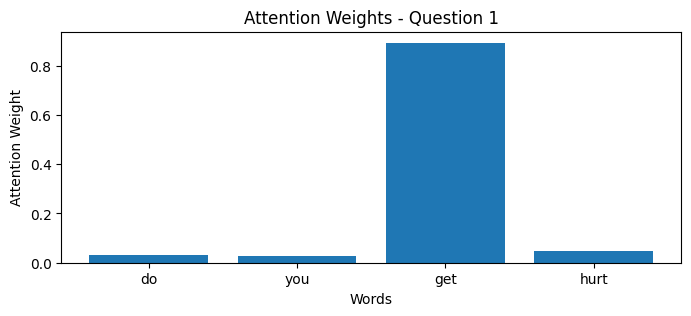

Question: do you get hurt?
Highest Attention Word: get



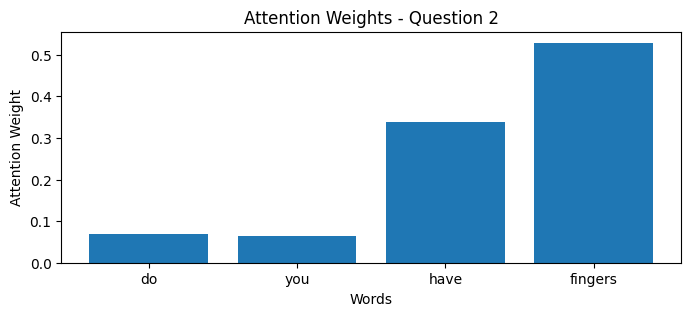

Question: do you have fingers?
Highest Attention Word: fingers



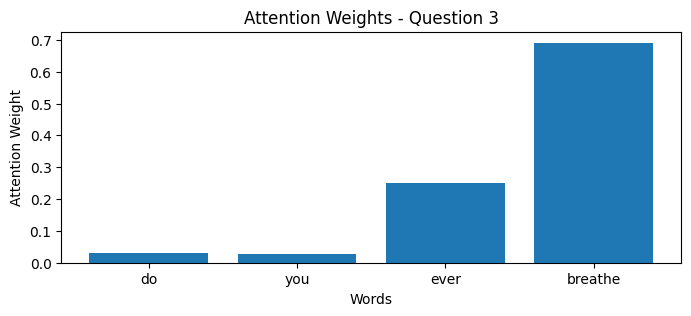

Question: do you ever breathe
Highest Attention Word: breathe



In [11]:
# Select three questions
indices = [0, 1, 2]

for i in indices:
    question = df["question"].iloc[i]

    token_ids = X[i]
    words = [
        tokenizer.index_word[int(t)]
        for t in token_ids if int(t) != 0
    ]

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    attention = weights[0, :len(words)].tolist()

    plt.figure(figsize=(8, 3))
    plt.bar(words, attention)
    plt.title(f"Attention Weights - Question {i+1}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.show()

    highest_word = words[attention.index(max(attention))]

    print("Question:", question)
    print("Highest Attention Word:", highest_word)
    print()

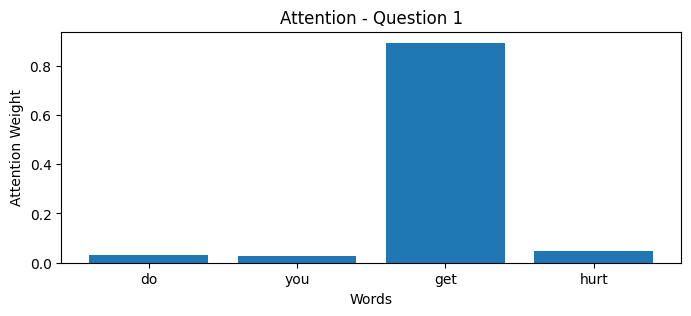

Question: do you get hurt?
Predicted Answer ID: 0
Highest Attention Word: get
Actual Answer ID: 0



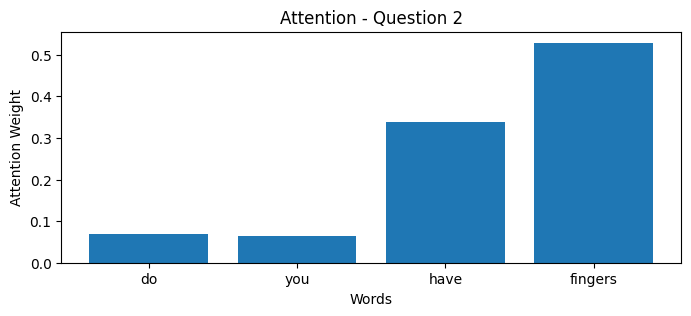

Question: do you have fingers?
Predicted Answer ID: 0
Highest Attention Word: fingers
Actual Answer ID: 0



In [12]:
# Select two similar questions
indices = [0, 1]

for i in indices:
    question = df["question"].iloc[i]

    token_ids = X[i]
    words = [
        tokenizer.index_word[int(t)]
        for t in token_ids if int(t) != 0
    ]

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    attention = weights[0, :len(words)].tolist()

    plt.figure(figsize=(8, 3))
    plt.bar(words, attention)
    plt.title(f"Attention - Question {i+1}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.show()

    predicted_id = prediction.argmax(dim=1).item()
    highest_word = words[attention.index(max(attention))]

    print("Question:", question)
    print("Predicted Answer ID:", predicted_id)
    print("Highest Attention Word:", highest_word)
    print("Actual Answer ID:", df["answer_id"].iloc[i])
    print()